# Mô hình toán đầy đủ: $S_a(t)$ và bão hoà tĩnh mạch $S_v(t)$ khi lặn

Notebook chạy toàn bộ mô hình trong ghi chú "Mô hình Toán" (E0, E1, $S_a(t)$ với $\Delta S_a(T_d)$, E2) trên dữ liệu đã merge (`penguin_merged.csv`, `penguin_dives.csv` từ `merge_data_new_v2`).

**Công thức:**

- **E0:** $S=\dfrac{P^{n}}{P_{50}^{n}+P^{n}}$, $P_{50}=28{,}2$ mmHg, $n=2{,}93$.
- **E1:** $t_{start}=t-t_{in\_dive}$; $t_{min}=(t-t_{start})/60$; $x=t_{min}/T_d$; $t_{end}=t_{start}+60T_d$; $z_{max}=\max(\text{depth})$.
- **$S_a(t)$:** $0{,}97$ nếu $t_{min}<0$; $0{,}987-\Delta S_a x^{5}$ nếu $0\le t_{min}\le T_d$; $0{,}97-(0{,}97-S_{end})e^{-(t_{min}-T_d)/\tau_a}$ nếu $t_{min}>T_d$; với $\Delta S_a=\mathrm{clip}(-0{,}141+0{,}183\ln T_d;\,0;\,0{,}6)$ và $S_{end}=0{,}987-\Delta S_a$.
- **E2:** $\dfrac{dS_v}{dt}=\dfrac{[S_a(t)-g(t)]-S_v}{r}$, với $g=m\,r$, $r=V_v/Q$. Rời rạc hoá bước $\Delta t=0{,}05$ phút: $S_{j+1}=S_je^{-\Delta t/r}+(1-e^{-\Delta t/r})\,[S_a(t_j)-g(t_j)]$.
- **$g(t)$ theo 6 giai đoạn:** $g_{rest}$ (trước lặn và sau lặn quá 3 phút), $g_1,g_2,g_3$ (ba đoạn bằng nhau của lần lặn, theo $x$), $g_{p1}$ (phút đầu sau lặn), $g_{p2}$ (phút 1–3 sau lặn).
- **Khớp:** cực tiểu $\sum_i(S_{v,i}-\hat S_v(t_i;\theta))^2$ với $\theta=(S_{init},g_{rest},g_1,g_2,g_3,g_{p1},g_{p2})$ cho **từng lần lặn**. Cửa sổ từ $t_{start}-300$ s đến $t_{end}+420$ s. Hai lựa chọn: **cả chu kỳ** (cửa sổ sạch, 7 tham số) và **chỉ lặn** (các dòng trong $[0,T_d]$, 4 tham số $S_{init},g_1,g_2,g_3$).

**Hai giá trị ghi chú không nêu, notebook ước lượng từ dữ liệu:** $\tau_a$ (hằng số hồi phục của $S_a$) và $r=V_v/Q$ (hằng số thời gian của hệ tĩnh mạch). Đặt `TAU_A` / `R_VEN` ở ô cấu hình nếu bạn đã có giá trị.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import lfilter
from scipy.optimize import least_squares, lsq_linear, minimize_scalar
from scipy.stats import mannwhitneyu
from matplotlib.ticker import ScalarFormatter

DIR = "../data"

# --- Hằng số trong ghi chú ---
P50, N_HILL = 28.2, 2.93
S_REST, S_DIVE0, K_EXP = 0.97, 0.987, 5
TD_MAX_ART = 11.7                 # T_d dài nhất của lần lặn động mạch (phút); trên mức này là ngoại suy
DT_MIN = 0.05                     # bước rời rạc hoá (phút)
PRE_WIN_S, POST_WIN_S = 300, 420  # cửa sổ: 5 phút trước, 7 phút sau lặn

def delta_Sa(Td):
    return np.clip(-0.141 + 0.183 * np.log(np.asarray(Td, dtype=float)), 0.0, 0.6)

# --- Ghi chú không nêu: để None thì notebook ước lượng từ dữ liệu ---
TAU_A = None                      # phút
R_VEN = None                      # phút

# --- Lựa chọn của notebook ---
G_MAX = 0.9                       # cận trên của g (phân số bão hoà); g >= 0
MIN_ROWS_FULL = 25                # tối thiểu số dòng trong cửa sổ để khớp cả chu kỳ
MIN_PER_SEG   = 2                 # tối thiểu số dòng trong mỗi giai đoạn của g
MIN_ROWS_DIVE = 9                 # tối thiểu số dòng trong [0, T_d] cho phương án chỉ lặn
PRE_MAX_MIN = POST_MAX_MIN = 10.0 # cửa sổ gán pha khi khớp S_a
N_BOOT, SEED = 300, 42

COL = {"Type A venous": "tab:orange", "Type B venous": "tab:green", "Arterial": "tab:red"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

## 1. Nạp dữ liệu, E0 và E1

In [2]:
ts    = pd.read_csv(f"{DIR}/penguin_merged.csv")
dives = pd.read_csv(f"{DIR}/penguin_dives.csv")
need = {"excluded_dive", "unlisted_dive", "t_in_dive_s", "dive_dur_min", "Hb", "PO2", "depth_m"}
assert need <= set(ts.columns), f"Thiếu cột {need - set(ts.columns)}: hãy chạy merge_data_new_v2 trước."

# --- E0 ---
def hill_sat(po2, p50=P50, n=N_HILL):
    po2 = np.asarray(po2, dtype=float)
    return po2**n / (p50**n + po2**n)

err = np.abs(hill_sat(ts["PO2"]) - ts["Hb"])
assert err.max() < 1e-3, "Cột Hb không khớp công thức Hill!"
print(f"E0: sai lệch tối đa giữa Hill(PO2) và Hb = {err.max()*100:.3f} %")

# --- E1 ---
ts["t_start"] = ts["t"] - ts["t_in_dive_s"]
inside = ts[ts["dive_id"].notna() & ~ts["excluded_dive"]]
assert inside.groupby("dive_id")["t_start"].agg(lambda s: s.max() - s.min()).max() < 1e-6

dv = inside.groupby("dive_id").agg(
    bird=("bird", "first"), site=("site", "first"), group=("group", "first"),
    t_start=("t_start", "first"), Td=("dive_dur_min", "first"),
    z_max=("depth_m", "max"), n_mau=("t", "size"))
dv["t_end"] = dv["t_start"] + 60.0 * dv["Td"]
chk = dv.join(dives.set_index("dive_id")["end"])
assert ((chk["t_end"] % 86400) - chk["end"]).abs().max() < 1.0
print(f"E1: {len(dv)} lần lặn hợp lệ có mẫu; t_end khớp giờ kết thúc trong bảng.")
display(dv.groupby("group").agg(so_lan_lan=("Td", "size"), Td_trung_vi=("Td", "median"), Td_max=("Td", "max"),
                                zmax_trung_vi=("z_max", "median")).round(2))

E0: sai lệch tối đa giữa Hill(PO2) và Hb = 0.052 %
E1: 156 lần lặn hợp lệ có mẫu; t_end khớp giờ kết thúc trong bảng.


,so_lan_lan,Td_trung_vi,Td_max,zmax_trung_vi
group,,,,
Arterial,63,5.27,11.68,22.50
Type A venous,28,3.03,9.08,21.25
Type B venous,65,8.98,23.13,50.00


## 2. Kiểm tra các nhận định trong ghi chú về $T_d$

Ghi chú nói $T_d\le 11{,}7$ phút là lần lặn động mạch dài nhất, và 16/65 lần lặn type B dài hơn mức đó (kết quả cho chúng là ngoại suy). Ô dưới kiểm tra lại và đánh dấu các lần lặn ngoại suy để dùng ở các biểu đồ sau.

In [3]:
art_Td_max = dv.loc[dv["site"] == "arterial", "Td"].max()
vB = dv[dv["group"] == "Type B venous"]
print(f"T_d động mạch dài nhất = {art_Td_max:.2f} phút (ghi chú: 11,7)")
print(f"Type B: {(vB['Td'] > TD_MAX_ART).sum()}/{len(vB)} lần lặn dài hơn {TD_MAX_ART} phút (ghi chú: 16/65)")
print(f"Type A: {(dv[dv['group']=='Type A venous']['Td'] > TD_MAX_ART).sum()} lần lặn dài hơn {TD_MAX_ART} phút")
dv["extrapolated"] = dv["Td"] > TD_MAX_ART

T_d động mạch dài nhất = 11.68 phút (ghi chú: 11,7)
Type B: 16/65 lần lặn dài hơn 11.7 phút (ghi chú: 16/65)
Type A: 0 lần lặn dài hơn 11.7 phút


## 3. Bão hoà động mạch $S_a(t)$

### 3a. Khung dữ liệu động mạch (trước / trong / sau lặn)
Mẫu ngoài lần lặn được gán cho lần lặn gần nhất (tối đa 10 phút trước hoặc sau); loại các dòng `unlisted_dive` và `excluded_dive`.

In [4]:
def Sa_template(t_min, Td, tau_a, s_rest=S_REST, s0=S_DIVE0, k=K_EXP):
    # S_a(t) theo ghi chú. t_min, Td: phút.
    t_min = np.asarray(t_min, dtype=float)
    Td    = np.asarray(Td, dtype=float)
    dS    = delta_Sa(Td)
    x     = np.clip(t_min / Td, 0.0, 1.0)
    s_end = s0 - dS
    dive  = s0 - dS * x**k
    post  = s_rest - (s_rest - s_end) * np.exp(-np.maximum(t_min - Td, 0.0) / tau_a)
    return np.where(t_min < 0, s_rest, np.where(t_min <= Td, dive, post))

def build_frame(site, pre_max=PRE_MAX_MIN, post_max=POST_MAX_MIN):
    parts = []
    for bird, g in ts[ts["site"] == site].groupby("bird"):
        d = dv[(dv["bird"] == bird) & (dv["site"] == site)].sort_values("t_start")
        if d.empty:
            continue
        st, en, ids, Td = d["t_start"].values, d["t_end"].values, d.index.values, d["Td"].values
        gi = g[g["dive_id"].isin(ids)].copy()
        gi["phase"] = "dive"; gi["ref"] = gi["dive_id"]
        gi["Td"] = gi["dive_id"].map(d["Td"]); gi["t_min"] = gi["t_in_dive_s"] / 60.0

        go = g[g["dive_id"].isna() & ~g["unlisted_dive"]].copy()
        t = go["t"].values
        i = np.searchsorted(st, t, side="right") - 1
        j = i + 1
        post = np.where(i >= 0, (t - en[np.clip(i, 0, None)]) / 60.0, np.nan)
        pre  = np.where(j < len(st), (st[np.clip(j, None, len(st) - 1)] - t) / 60.0, np.nan)
        ok_post = (post >= 0) & (post <= post_max)
        ok_pre  = (pre > 0) & (pre <= pre_max)
        use_post = ok_post & (~ok_pre | (post <= pre))
        use_pre  = ok_pre & (~ok_post | (pre < post))
        keep = use_post | use_pre
        go = go[keep].copy()
        is_post = use_post[keep]
        ref_idx = np.where(is_post, i[keep], j[keep])
        go["phase"] = np.where(is_post, "post", "pre")
        go["ref"]   = ids[ref_idx]
        go["Td"]    = Td[ref_idx]
        go["t_min"] = np.where(is_post, Td[ref_idx] + post[keep], -pre[keep])
        parts += [gi, go]
    f = pd.concat(parts, ignore_index=True)
    f["x"] = f["t_min"] / f["Td"]
    f["S"] = f["Hb"]
    f["group"] = f["ref"].map(dv["group"])
    f["z_max"] = f["ref"].map(dv["z_max"])
    return f[["bird", "site", "group", "ref", "phase", "t", "t_min", "Td", "x", "S", "PO2", "depth_m", "z_max"]]

A = build_frame("arterial")
display(A.groupby(["bird", "phase"]).size().unstack(fill_value=0))
print("Số lần lặn động mạch:", A["ref"].nunique())

phase,dive,post,pre
bird,,,
EP01,1156,629,566
EP02,13,4,0
EP08,720,532,532
EP10,666,641,658
EP36A,87,22,17


Số lần lặn động mạch: 63


### 3b. Kiểm tra công thức $\Delta S_a(T_d)$

Ghi chú cho $\Delta S_a=\mathrm{clip}(-0{,}141+0{,}183\ln T_d;0;0{,}6)$ (lặn càng dài thì tụt càng sâu). Mình đối chiếu với hai cách ước lượng từ dữ liệu: (i) khớp $x^5$ riêng từng lần lặn, (ii) mức tụt đến đáy $0{,}987-\min S$.

Ghi chú            : ΔS_a = -0.141 + 0.183 ln T_d
Khớp x^5 từng lần  : ΔS_a = -0.042 + 0.149 ln T_d  (n=63)
Mức tụt đến đáy    : ΔS_a = -0.107 + 0.187 ln T_d


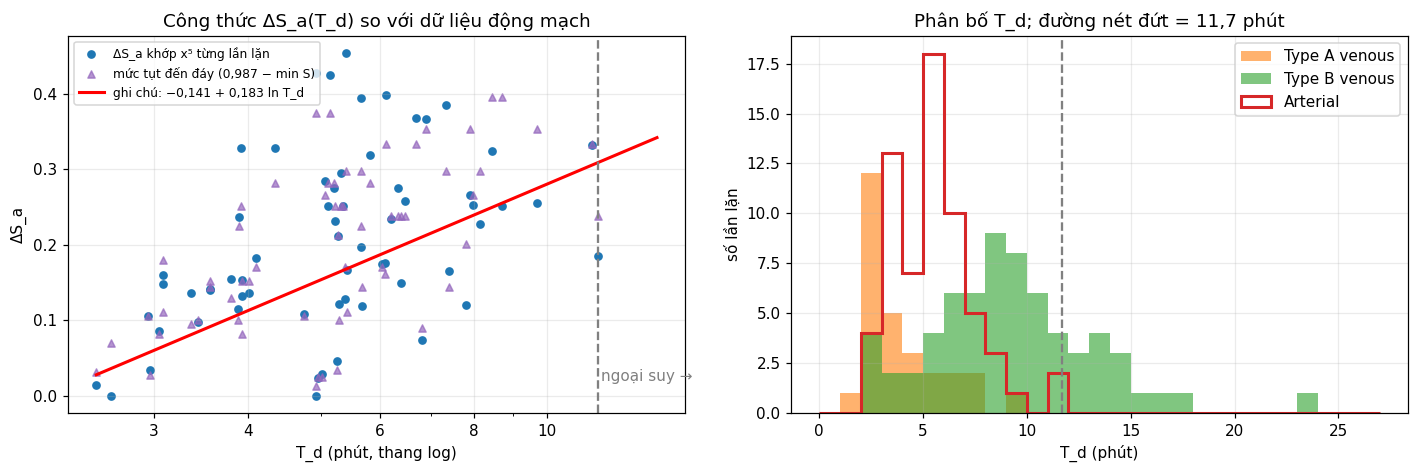

In [5]:
rows = []
for ref, g in A[A["phase"] == "dive"].groupby("ref"):
    if len(g) < 10:
        continue
    Td = g["Td"].iloc[0]; x = g["x"].values; y = g["S"].values
    r_ = least_squares(lambda p: S_DIVE0 - p[0] * x**K_EXP - y, [0.2], bounds=(0, 0.9))
    rows.append({"ref": ref, "Td": Td, "dSa_x5": r_.x[0], "drop_min": S_DIVE0 - y.min()})
P = pd.DataFrame(rows)
lnT = np.log(P["Td"])
b_x5  = np.polyfit(lnT, P["dSa_x5"], 1)
b_min = np.polyfit(lnT, P["drop_min"], 1)
print(f"Ghi chú            : ΔS_a = -0.141 + 0.183 ln T_d")
print(f"Khớp x^5 từng lần  : ΔS_a = {b_x5[1]:.3f} + {b_x5[0]:.3f} ln T_d  (n={len(P)})")
print(f"Mức tụt đến đáy    : ΔS_a = {b_min[1]:.3f} + {b_min[0]:.3f} ln T_d")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
tg = np.linspace(P["Td"].min(), 14, 200)
ax[0].scatter(P["Td"], P["dSa_x5"], s=22, color="tab:blue", label="ΔS_a khớp x⁵ từng lần lặn")
ax[0].scatter(P["Td"], P["drop_min"], s=22, marker="^", color="tab:purple", alpha=0.7, label="mức tụt đến đáy (0,987 − min S)")
ax[0].plot(tg, delta_Sa(tg), "r-", lw=2, label="ghi chú: −0,141 + 0,183 ln T_d")
ax[0].axvline(TD_MAX_ART, color="gray", ls="--"); ax[0].text(TD_MAX_ART + 0.1, 0.02, "ngoại suy →", color="gray")
ax[0].set(xscale="log", xlabel="T_d (phút, thang log)", ylabel="ΔS_a", title="Công thức ΔS_a(T_d) so với dữ liệu động mạch")
ax[0].set_xticks([3, 4, 6, 8, 10]); ax[0].xaxis.set_major_formatter(ScalarFormatter())
ax[0].legend(fontsize=8)

bins = np.arange(0, 28, 1.0)
for grp in ["Type A venous", "Type B venous"]:
    ax[1].hist(dv.loc[dv["group"] == grp, "Td"], bins=bins, alpha=0.6, color=COL[grp], label=grp)
ax[1].hist(dv.loc[dv["site"] == "arterial", "Td"], bins=bins, histtype="step", lw=2, color=COL["Arterial"], label="Arterial")
ax[1].axvline(TD_MAX_ART, color="gray", ls="--")
ax[1].set(xlabel="T_d (phút)", ylabel="số lần lặn", title="Phân bố T_d; đường nét đứt = 11,7 phút")
ax[1].legend()
plt.tight_layout(); plt.show()

### 3c. Ước lượng $\tau_a$ và đánh giá $S_a(t)$

In [6]:
if TAU_A is None:
    f = lambda p: Sa_template(A["t_min"], A["Td"], p[0]) - A["S"]
    TAU_A_FIT = float(least_squares(f, [1.0], bounds=(0.05, 30)).x[0])
    # khoảng tin cậy bootstrap theo lần lặn
    rng = np.random.default_rng(SEED)
    by = {k: v for k, v in A.groupby("ref")}; ids_a = np.array(list(by))
    bt = []
    for _ in range(N_BOOT):
        fr = pd.concat([by[i] for i in rng.choice(ids_a, len(ids_a), replace=True)])
        bt.append(least_squares(lambda p: Sa_template(fr["t_min"], fr["Td"], p[0]) - fr["S"], [1.0], bounds=(0.05, 30)).x[0])
    tau_ci = np.percentile(bt, [2.5, 97.5])
    print(f"τ_a ước lượng = {TAU_A_FIT:.3f} phút  (KTC 95 % bootstrap: {tau_ci[0]:.2f}–{tau_ci[1]:.2f})")
else:
    TAU_A_FIT, tau_ci = float(TAU_A), (np.nan, np.nan)
    print(f"τ_a đặt tay = {TAU_A_FIT} phút")
TAU = TAU_A_FIT

A["pred"] = Sa_template(A["t_min"], A["Td"], TAU)
A["res"]  = A["S"] - A["pred"]
rmse = lambda x: float(np.sqrt(np.mean(np.square(x))))
print("\nSai số S_a theo pha (quan sát − mô hình):")
display(A.groupby("phase")["res"].agg(n="size", bias="mean", rmse=rmse).round(4))

τ_a ước lượng = 1.578 phút  (KTC 95 % bootstrap: 1.35–2.02)

Sai số S_a theo pha (quan sát − mô hình):


,n,bias,rmse
phase,,,
dive,2642,-0.0028,0.0423
post,1828,-0.0240,0.0639
pre,1773,-0.0244,0.0329


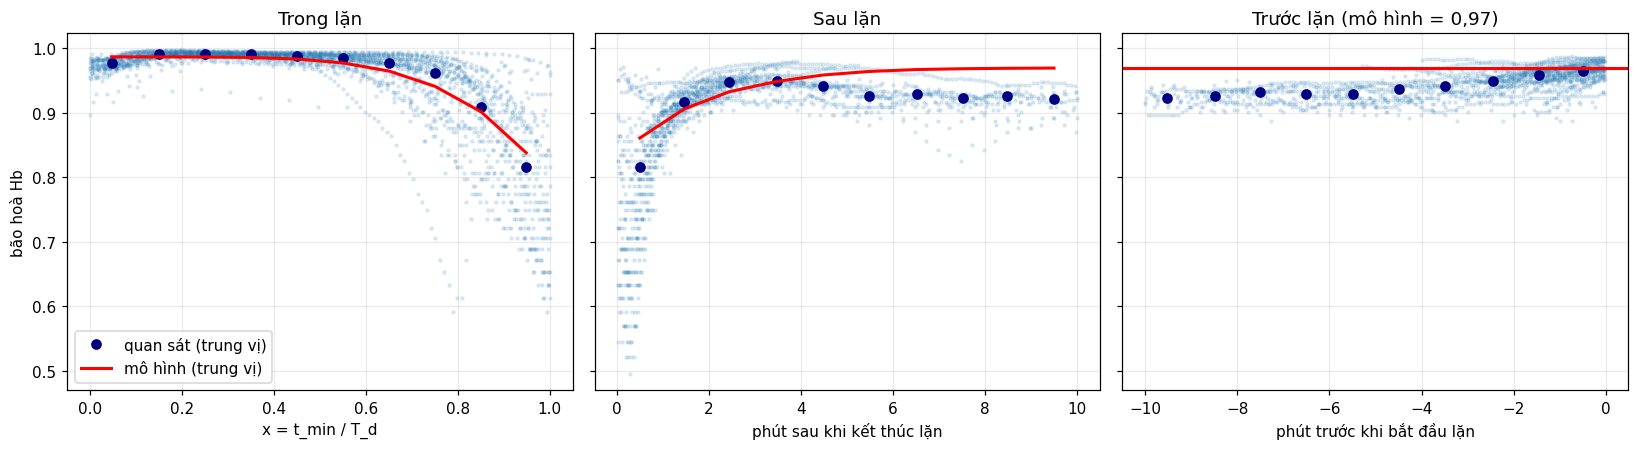

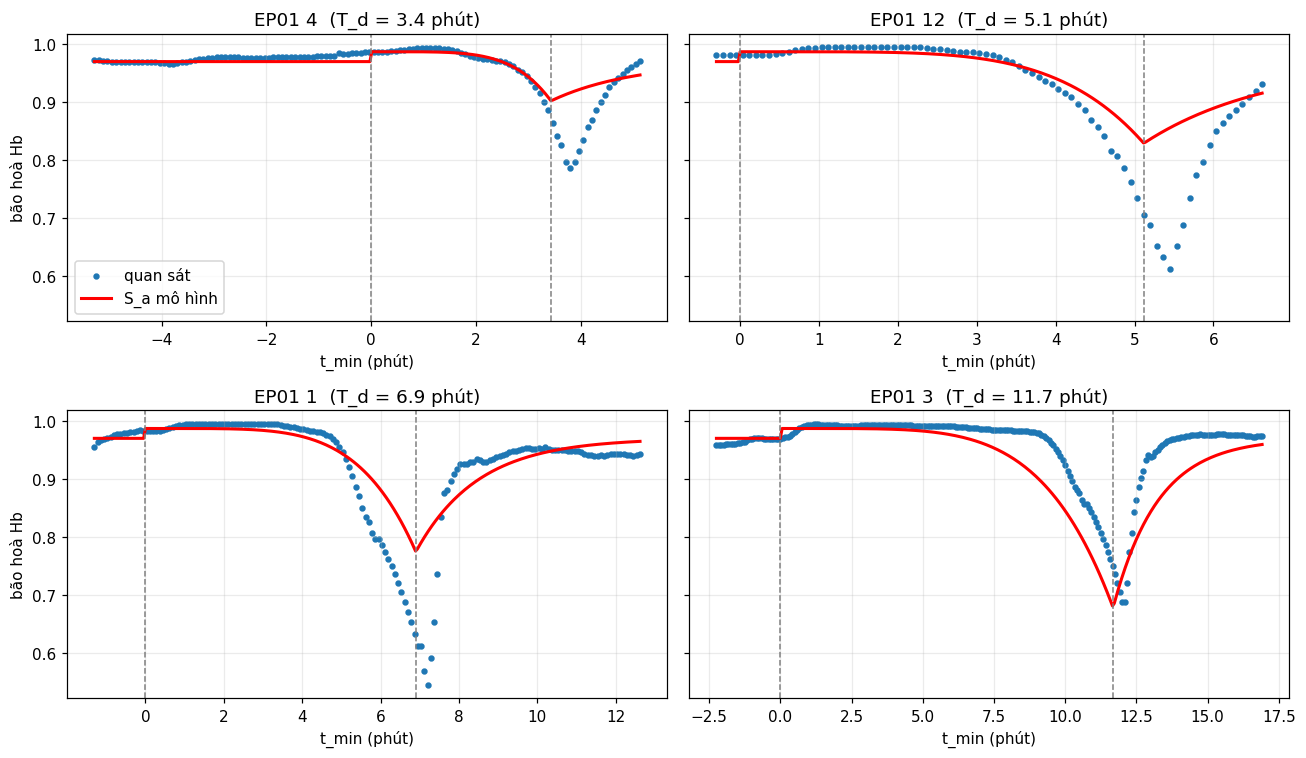

In [7]:
def binned_median(x, y, edges, min_n=5):
    x, y = np.asarray(x), np.asarray(y)
    idx = np.digitize(x, edges) - 1
    xs, ys = [], []
    for b in range(len(edges) - 1):
        m = idx == b
        if m.sum() >= min_n:
            xs.append(np.median(x[m])); ys.append(np.median(y[m]))
    return np.array(xs), np.array(ys)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
d = A[A["phase"] == "dive"]
ax[0].scatter(d["x"], d["S"], s=4, alpha=0.12, color="tab:blue")
bx, by_ = binned_median(d["x"], d["S"], np.linspace(0, 1, 11)); ax[0].plot(bx, by_, "o", color="navy", label="quan sát (trung vị)")
bx, bp = binned_median(d["x"], d["pred"], np.linspace(0, 1, 11)); ax[0].plot(bx, bp, "r-", lw=2, label="mô hình (trung vị)")
ax[0].set(title="Trong lặn", xlabel="x = t_min / T_d", ylabel="bão hoà Hb"); ax[0].legend()

p_ = A[A["phase"] == "post"]; u = p_["t_min"] - p_["Td"]; e = np.linspace(0, POST_MAX_MIN, 11)
ax[1].scatter(u, p_["S"], s=4, alpha=0.12, color="tab:blue")
bx, by_ = binned_median(u, p_["S"], e); ax[1].plot(bx, by_, "o", color="navy")
bx, bp = binned_median(u, p_["pred"], e); ax[1].plot(bx, bp, "r-", lw=2)
ax[1].set(title="Sau lặn", xlabel="phút sau khi kết thúc lặn")

q = A[A["phase"] == "pre"]; e = np.linspace(-PRE_MAX_MIN, 0, 11)
ax[2].scatter(q["t_min"], q["S"], s=4, alpha=0.12, color="tab:blue")
bx, by_ = binned_median(q["t_min"], q["S"], e); ax[2].plot(bx, by_, "o", color="navy")
ax[2].axhline(S_REST, color="r", lw=2); ax[2].set(title="Trước lặn (mô hình = 0,97)", xlabel="phút trước khi bắt đầu lặn")
plt.tight_layout(); plt.show()

cand = A[A["phase"] == "dive"].groupby("ref").agg(n=("t", "size"), Td=("Td", "first"))
cand = cand[cand["n"] >= 40].sort_values("Td")
pick = cand.index[np.linspace(0, len(cand) - 1, 4).astype(int)]
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for a, did in zip(axs.ravel(), pick):
    g = A[A["ref"] == did].sort_values("t_min"); Td = g["Td"].iloc[0]
    a.scatter(g["t_min"], g["S"], s=10, color="tab:blue", label="quan sát")
    tgrid = np.linspace(g["t_min"].min(), g["t_min"].max(), 300)
    a.plot(tgrid, Sa_template(tgrid, Td, TAU), "r-", lw=2, label="S_a mô hình")
    a.axvline(0, color="gray", ls="--", lw=1); a.axvline(Td, color="gray", ls="--", lw=1)
    a.set(title=f"{did}  (T_d = {Td:.1f} phút)", xlabel="t_min (phút)")
axs[0, 0].set_ylabel("bão hoà Hb"); axs[1, 0].set_ylabel("bão hoà Hb"); axs[0, 0].legend()
plt.tight_layout(); plt.show()

## 4. E2 — Phương trình chính cho $S_v(t)$

**Cài đặt.** Với $S_a$ và $r$ cố định, đầu ra $\hat S_v$ **tuyến tính** theo $\theta=(S_{init},g_{rest},g_1,\dots,g_{p2})$, vì công thức truy hồi chỉ cộng các đáp ứng bậc nhất. Notebook dùng điều này để khớp bằng bình phương tối thiểu tuyến tính có cận ($0\le g\le 0{,}9$, $0\le S_{init}\le 1$), nhanh và không kẹt cực tiểu cục bộ.

Để chắc chắn cách làm này đúng với công thức gốc, hàm `simulate_Sv` viết **đúng như ghi chú** bằng vòng lặp $S_{j+1}=S_je^{-\Delta t/r}+(1-e^{-\Delta t/r})[S_a(t_j)-g(t_j)]$, và ô kiểm thử bên dưới sinh dữ liệu từ nó rồi kiểm tra bộ khớp tìm lại đúng $\theta$.

In [8]:
SEG_NAMES = {0: "g_rest", 1: "g1", 2: "g2", 3: "g3", 4: "g_p1", 5: "g_p2"}
G_COLS = list(SEG_NAMES.values())

def seg_index(t_min, Td):
    # chỉ số giai đoạn của g(t): 0 = g_rest (t<0 hoặc t > T_d+3), 1-3 = ba đoạn lặn theo x, 4 = g_p1, 5 = g_p2
    t = np.asarray(t_min, dtype=float)
    s = np.zeros(t.shape, dtype=int)
    s = np.where((t >= 0) & (t < Td / 3), 1, s)
    s = np.where((t >= Td / 3) & (t < 2 * Td / 3), 2, s)
    s = np.where((t >= 2 * Td / 3) & (t <= Td), 3, s)
    s = np.where((t > Td) & (t <= Td + 1), 4, s)
    s = np.where((t > Td + 1) & (t <= Td + 3), 5, s)
    return s

def simulate_Sv(theta, Td, r, tau_a, t0, t1):
    # Mô phỏng ĐÚNG công thức ghi chú bằng vòng lặp. theta: dict S_init và các g.
    n  = int(np.ceil((t1 - t0) / DT_MIN)) + 1
    tg = t0 + DT_MIN * np.arange(n)
    a  = np.exp(-DT_MIN / r)
    sa = Sa_template(tg, Td, tau_a)
    gv = np.array([theta.get(SEG_NAMES[k], 0.0) for k in range(6)])[seg_index(tg, Td)]
    S  = np.empty(n); S[0] = theta["S_init"]
    for j in range(n - 1):
        S[j + 1] = S[j] * a + (1 - a) * (sa[j] - gv[j])
    return tg, S

def _basis(Td, t_obs, r, tau_a, option):
    t_obs = np.asarray(t_obs, dtype=float)
    t0 = 0.0 if option == "dive" else max(-PRE_WIN_S / 60.0, float(t_obs.min()))
    t1 = float(t_obs.max())
    n  = int(np.ceil((t1 - t0) / DT_MIN)) + 1
    tg = t0 + DT_MIN * np.arange(n)
    a, c = np.exp(-DT_MIN / r), 1 - np.exp(-DT_MIN / r)
    filt = lambda u: lfilter([0.0, c], [1.0, -a], u)
    sg   = seg_index(tg, Td)
    segs = [1, 2, 3] if option == "dive" else [0, 1, 2, 3, 4, 5]
    cols = [a ** np.arange(n)] + [-filt((sg == k).astype(float)) for k in segs]
    B  = np.column_stack([np.interp(t_obs, tg, col) for col in cols])
    b0 = np.interp(t_obs, tg, filt(Sa_template(tg, Td, tau_a)))
    return B, b0, segs

def fit_dive(t_obs, y_obs, Td, r, tau_a, option="full"):
    # option 'full': 7 tham số, cửa sổ cả chu kỳ. option 'dive': S_init, g1, g2, g3, chỉ dòng trong [0, T_d].
    y = np.asarray(y_obs, dtype=float)
    B, b0, segs = _basis(Td, t_obs, r, tau_a, option)
    lo = [0.0] * (1 + len(segs)); hi = [1.0] + [G_MAX] * len(segs)
    sol = lsq_linear(B, y - b0, bounds=(lo, hi))
    theta = dict(zip(["S_init"] + [SEG_NAMES[k] for k in segs], sol.x))
    return theta, b0 + B @ sol.x

# ---- Kiểm thử: dữ liệu giả từ simulate_Sv, bộ khớp phải tìm lại đúng tham số ----
true = {"S_init": 0.62, "g_rest": 0.08, "g1": 0.15, "g2": 0.35, "g3": 0.50, "g_p1": 0.45, "g_p2": 0.20}
Td_t, r_t, tau_t = 8.0, 0.75, 1.5
tg_, S_ = simulate_Sv(true, Td_t, r_t, tau_t, -5.0, Td_t + 7.0)
t_obs = np.arange(-5.0, Td_t + 7.0, 0.25)
y_obs = np.interp(t_obs, tg_, S_)
th_f, pred_f = fit_dive(t_obs, y_obs, Td_t, r_t, tau_t, "full")
err_f = max(abs(th_f[k] - true[k]) for k in true)
m = (t_obs >= 0) & (t_obs <= Td_t)
th_d, _ = fit_dive(t_obs[m], y_obs[m], Td_t, r_t, tau_t, "dive")
tg_d, S_d = simulate_Sv({"S_init": 0.62, "g1": 0.15, "g2": 0.35, "g3": 0.50}, Td_t, r_t, tau_t, 0.0, Td_t)
y_d = np.interp(t_obs[m], tg_d, S_d)
th_d, _ = fit_dive(t_obs[m], y_d, Td_t, r_t, tau_t, "dive")
err_d = max(abs(th_d[k] - v) for k, v in {"S_init": 0.62, "g1": 0.15, "g2": 0.35, "g3": 0.50}.items())
print(f"Kiểm thử cả chu kỳ : sai số tham số lớn nhất = {err_f:.2e}")
print(f"Kiểm thử chỉ lặn   : sai số tham số lớn nhất = {err_d:.2e}")
assert err_f < 1e-4 and err_d < 1e-4, "Bộ khớp không tìm lại được tham số gốc!"

Kiểm thử cả chu kỳ : sai số tham số lớn nhất = 7.77e-16
Kiểm thử chỉ lặn   : sai số tham số lớn nhất = 3.33e-16


## 5. Cửa sổ khớp và cửa sổ sạch

Mỗi lần lặn tĩnh mạch có cửa sổ $[t_{start}-300\,\mathrm{s},\;t_{end}+420\,\mathrm{s}]$ cùng chim và cùng site. Cửa sổ **sạch** là cửa sổ không chứa lần lặn nào khác (kể cả đợt lặn `unlisted_dive` không có trong bảng và các lần lặn không có mẫu). Ghi chú cũng dự đoán type A thường không có cửa sổ sạch vì lặn liên tiếp, ô dưới kiểm tra điều đó.

Lần lặn không có mẫu (kiểm tra chồng lấn theo giờ trong ngày): ['EP36A 8', 'EP07 9', 'EP07 10']


,so_lan_lan,cua_so_sach,co_lan_lan_khac,co_unlisted,du_dieu_kien_ca_chu_ky,du_dieu_kien_chi_lan
group,,,,,,
Type A venous,28,3,24,7,3,26
Type B venous,65,28,29,17,28,64


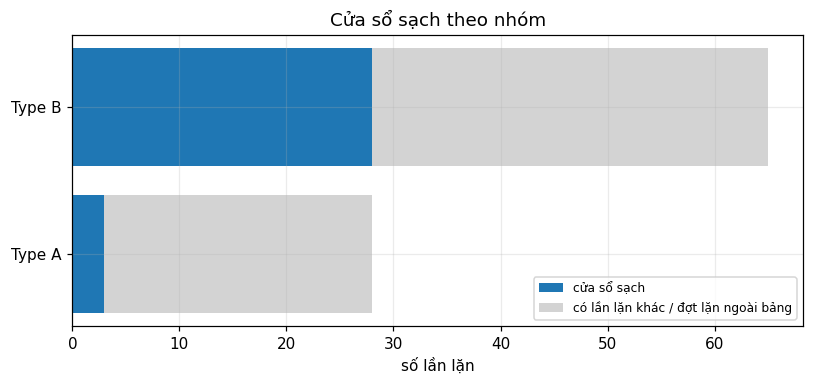

In [9]:
all_dv = ts[ts["dive_id"].notna()].groupby("dive_id").agg(
    bird=("bird", "first"), site=("site", "first"), t_start=("t_start", "first"), Td=("dive_dur_min", "first"))
all_dv["t_end"] = all_dv["t_start"] + 60.0 * all_dv["Td"]
no_rows = dives[~dives["dive_id"].isin(all_dv.index)]          # lần lặn không có mẫu: chỉ biết giờ trong ngày
print("Lần lặn không có mẫu (kiểm tra chồng lấn theo giờ trong ngày):", no_rows["dive_id"].tolist())

def get_window(did):
    d = dv.loc[did]
    W0, W1 = d["t_start"] - PRE_WIN_S, d["t_end"] + POST_WIN_S
    g = ts[(ts["bird"] == d["bird"]) & (ts["site"] == d["site"]) & (ts["t"] >= W0) & (ts["t"] <= W1)].copy()
    g["t_min"] = (g["t"] - d["t_start"]) / 60.0
    oth = all_dv[(all_dv["bird"] == d["bird"]) & (all_dv["site"] == d["site"]) & (all_dv.index != did)]
    other = bool(((oth["t_start"] < W1) & (oth["t_end"] > W0)).any())
    for m in no_rows[no_rows["bird"] == d["bird"]].itertuples():
        if m.start < (W1 % 86400) and m.end > (W0 % 86400):
            other = True
    unl = bool(g["unlisted_dive"].any())
    return g, other, unl

ven = dv[dv["site"] == "venous"].copy()
WIN, rows = {}, []
for did, d in ven.iterrows():
    g, other, unl = get_window(did)
    WIN[did] = g
    sc = np.bincount(seg_index(g["t_min"], d["Td"]), minlength=6)
    inwin = g[(g["t_min"] >= 0) & (g["t_min"] <= d["Td"])]
    rows.append({"dive_id": did, "group": d["group"], "Td": d["Td"], "n_window": len(g), "other_dive": other, "unlisted": unl,
                 "n_dive_rows": len(inwin), **{f"n_{SEG_NAMES[k]}": sc[k] for k in range(6)}})
W = pd.DataFrame(rows).set_index("dive_id")
W["clean"] = ~W["other_dive"] & ~W["unlisted"]
W["ok_full"] = W["clean"] & (W["n_window"] >= MIN_ROWS_FULL) & (W[[f"n_{n}" for n in G_COLS]].min(axis=1) >= MIN_PER_SEG)
thirds = W[["n_g1", "n_g2", "n_g3"]].min(axis=1)
W["ok_dive"] = (W["n_dive_rows"] >= MIN_ROWS_DIVE) & (thirds >= MIN_PER_SEG)

summary = W.groupby("group").agg(so_lan_lan=("Td", "size"), cua_so_sach=("clean", "sum"), co_lan_lan_khac=("other_dive", "sum"),
                                 co_unlisted=("unlisted", "sum"), du_dieu_kien_ca_chu_ky=("ok_full", "sum"), du_dieu_kien_chi_lan=("ok_dive", "sum"))
display(summary)

fig, ax = plt.subplots(1, 1, figsize=(7.5, 3.6))
lab = {"clean": "cửa sổ sạch", "dirty": "có lần lặn khác / đợt lặn ngoài bảng"}
for k, grp in enumerate(["Type A venous", "Type B venous"]):
    s = W[W["group"] == grp]
    ax.barh(k, s["clean"].sum(), color="tab:blue", label=lab["clean"] if k == 0 else None)
    ax.barh(k, (~s["clean"]).sum(), left=s["clean"].sum(), color="lightgray", label=lab["dirty"] if k == 0 else None)
ax.set_yticks([0, 1]); ax.set_yticklabels(["Type A", "Type B"]); ax.set_xlabel("số lần lặn"); ax.set_title("Cửa sổ sạch theo nhóm"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## 6. Chọn $r=V_v/Q$

Ghi chú không cho giá trị $r$. Vì $r$ quyết định tốc độ $S_v$ đuổi theo $S_a-g$, nó được xác định rõ từ các đoạn chuyển tiếp (sau lặn) của các cửa sổ sạch. Ô dưới quét $r$ và chọn giá trị làm tổng sai số của phương án **cả chu kỳ** nhỏ nhất.

r ước lượng = 0.764 phút (RMSE gộp 0.0666, trên 31 cửa sổ sạch)


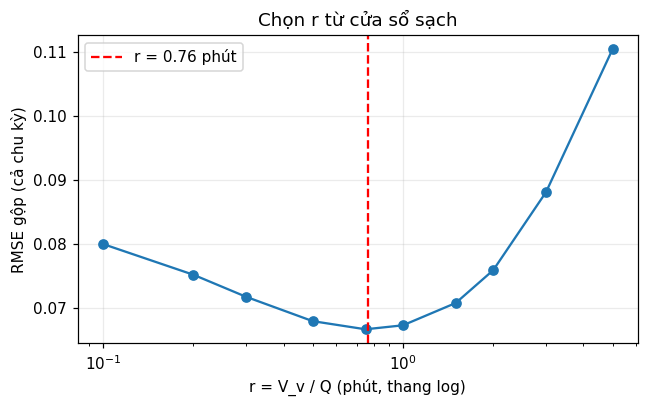

In [10]:
ids_full = W.index[W["ok_full"]].tolist()
assert len(ids_full) >= 5, "Quá ít cửa sổ sạch để ước lượng r"

def total_rmse(r, ids):
    sse, n = 0.0, 0
    for did in ids:
        g = WIN[did]; _, pred = fit_dive(g["t_min"], g["Hb"], ven.loc[did, "Td"], r, TAU, "full")
        sse += np.sum((g["Hb"].values - pred) ** 2); n += len(g)
    return np.sqrt(sse / n)

grid = np.array([0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0])
prof = np.array([total_rmse(r, ids_full) for r in grid])
if R_VEN is None:
    opt = minimize_scalar(lambda r: total_rmse(r, ids_full), bounds=(0.2, 3.0), method="bounded")
    R = float(opt.x)
    print(f"r ước lượng = {R:.3f} phút (RMSE gộp {opt.fun:.4f}, trên {len(ids_full)} cửa sổ sạch)")
else:
    R = float(R_VEN); print(f"r đặt tay = {R} phút")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(grid, prof, "o-"); ax.axvline(R, color="r", ls="--", label=f"r = {R:.2f} phút")
ax.set(xscale="log", xlabel="r = V_v / Q (phút, thang log)", ylabel="RMSE gộp (cả chu kỳ)", title="Chọn r từ cửa sổ sạch"); ax.legend()
plt.tight_layout(); plt.show()

## 7. Khớp từng lần lặn

- **Cả chu kỳ:** cửa sổ sạch, 7 tham số $(S_{init},g_{rest},g_1,g_2,g_3,g_{p1},g_{p2})$.
- **Chỉ lặn:** các dòng trong $[0,T_d]$, 4 tham số $(S_{init},g_1,g_2,g_3)$; dùng được cho cả type A (phần lớn không có cửa sổ sạch).

In [11]:
def run_fits(option, ids):
    out = []
    for did in ids:
        d = ven.loc[did]; g = WIN[did]
        if option == "dive":
            g = g[(g["t_min"] >= 0) & (g["t_min"] <= d["Td"])]
        th, pred = fit_dive(g["t_min"], g["Hb"], d["Td"], R, TAU, option)
        out.append({"dive_id": did, "bird": d["bird"], "group": d["group"], "Td": d["Td"], "z_max": d["z_max"],
                    "extrapolated": bool(d["Td"] > TD_MAX_ART), "n_rows": len(g),
                    "rmse": rmse(g["Hb"].values - pred), **th})
    return pd.DataFrame(out).set_index("dive_id")

F = run_fits("full", W.index[W["ok_full"]])
G = run_fits("dive", W.index[W["ok_dive"]])
print(f"Cả chu kỳ: {len(F)} lần lặn {F['group'].value_counts().to_dict()}")
print(f"Chỉ lặn  : {len(G)} lần lặn {G['group'].value_counts().to_dict()}")

print("\nCả chu kỳ: trung vị tham số theo nhóm")
display(F.groupby("group")[["n_rows", "rmse", "S_init"] + G_COLS].median().round(3))
print("Chỉ lặn: trung vị tham số theo nhóm")
display(G.groupby("group")[["n_rows", "rmse", "S_init", "g1", "g2", "g3"]].median().round(3))

for name, T in [("cả chu kỳ", F), ("chỉ lặn", G)]:
    cols = [c for c in G_COLS if c in T.columns]
    lo = {c: round(float((T[c] < 1e-6).mean()), 2) for c in cols}; hi = {c: round(float((T[c] > G_MAX - 1e-6).mean()), 2) for c in cols}
    print(f"Tỉ lệ tham số chạm cận ({name}) - cận 0: {lo} | cận {G_MAX}: {hi}")

Cả chu kỳ: 31 lần lặn {'Type B venous': 28, 'Type A venous': 3}
Chỉ lặn  : 90 lần lặn {'Type B venous': 64, 'Type A venous': 26}

Cả chu kỳ: trung vị tham số theo nhóm


,n_rows,rmse,S_init,g_rest,g1,g2,g3,g_p1,g_p2
group,,,,,,,,,
Type A venous,73.0,0.07,0.654,0.193,0.000,0.000,0.559,0.375,0.090
Type B venous,85.0,0.06,0.645,0.258,0.522,0.536,0.417,0.462,0.187


Chỉ lặn: trung vị tham số theo nhóm


,n_rows,rmse,S_init,g1,g2,g3
group,,,,,,
Type A venous,15.0,0.018,0.839,0.034,0.069,0.152
Type B venous,39.5,0.047,0.817,0.380,0.488,0.388


Tỉ lệ tham số chạm cận (cả chu kỳ) - cận 0: {'g_rest': 0.0, 'g1': 0.06, 'g2': 0.06, 'g3': 0.0, 'g_p1': 0.03, 'g_p2': 0.1} | cận 0.9: {'g_rest': 0.0, 'g1': 0.03, 'g2': 0.0, 'g3': 0.0, 'g_p1': 0.0, 'g_p2': 0.0}
Tỉ lệ tham số chạm cận (chỉ lặn) - cận 0: {'g1': 0.1, 'g2': 0.08, 'g3': 0.07} | cận 0.9: {'g1': 0.01, 'g2': 0.0, 'g3': 0.0}


## 8. Biểu đồ

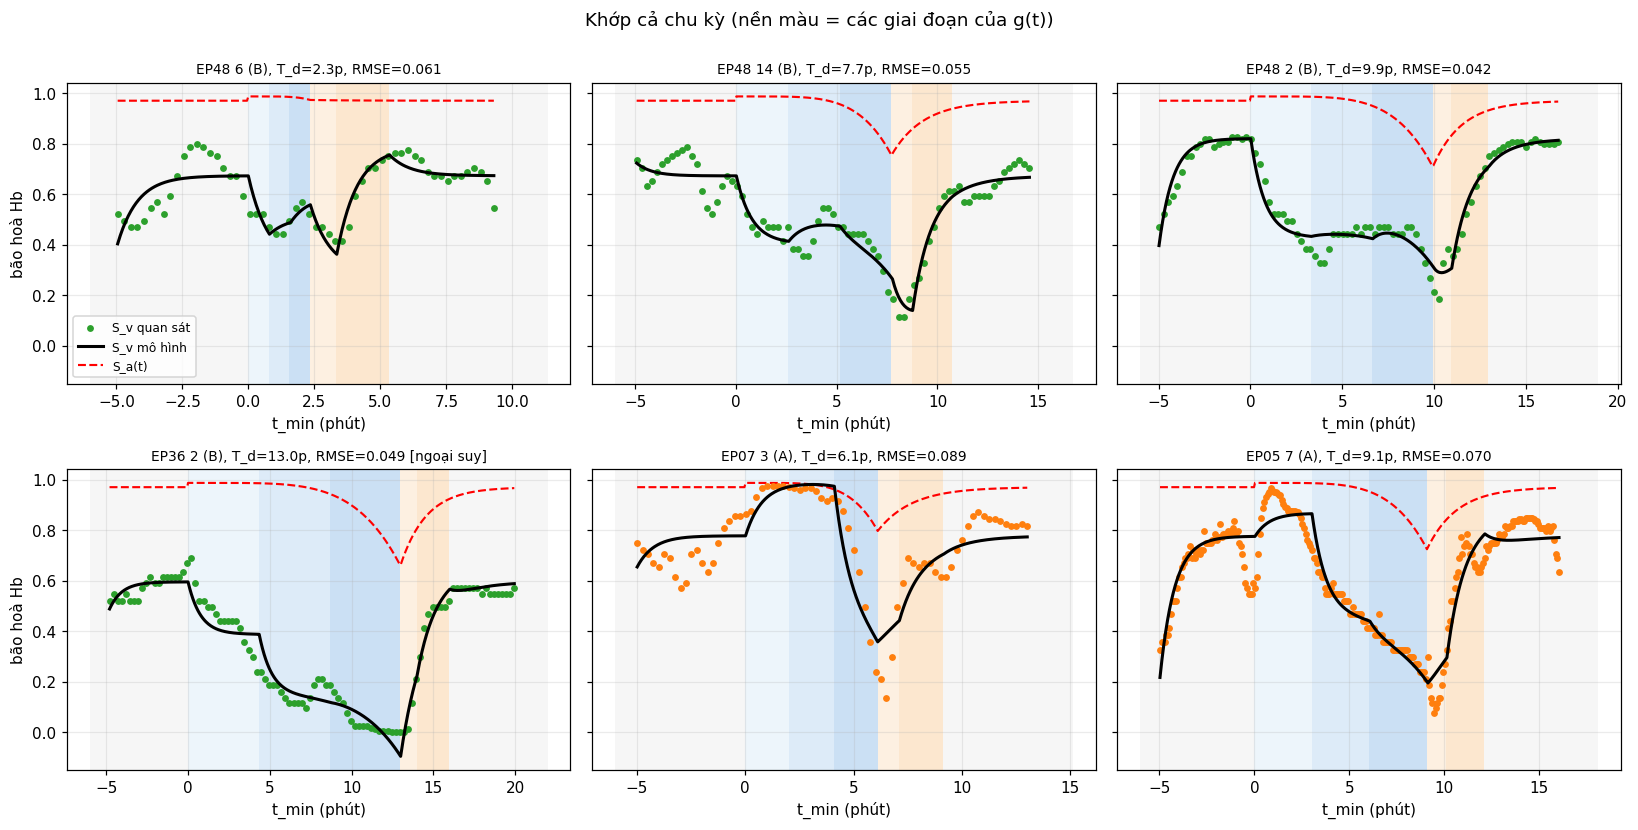

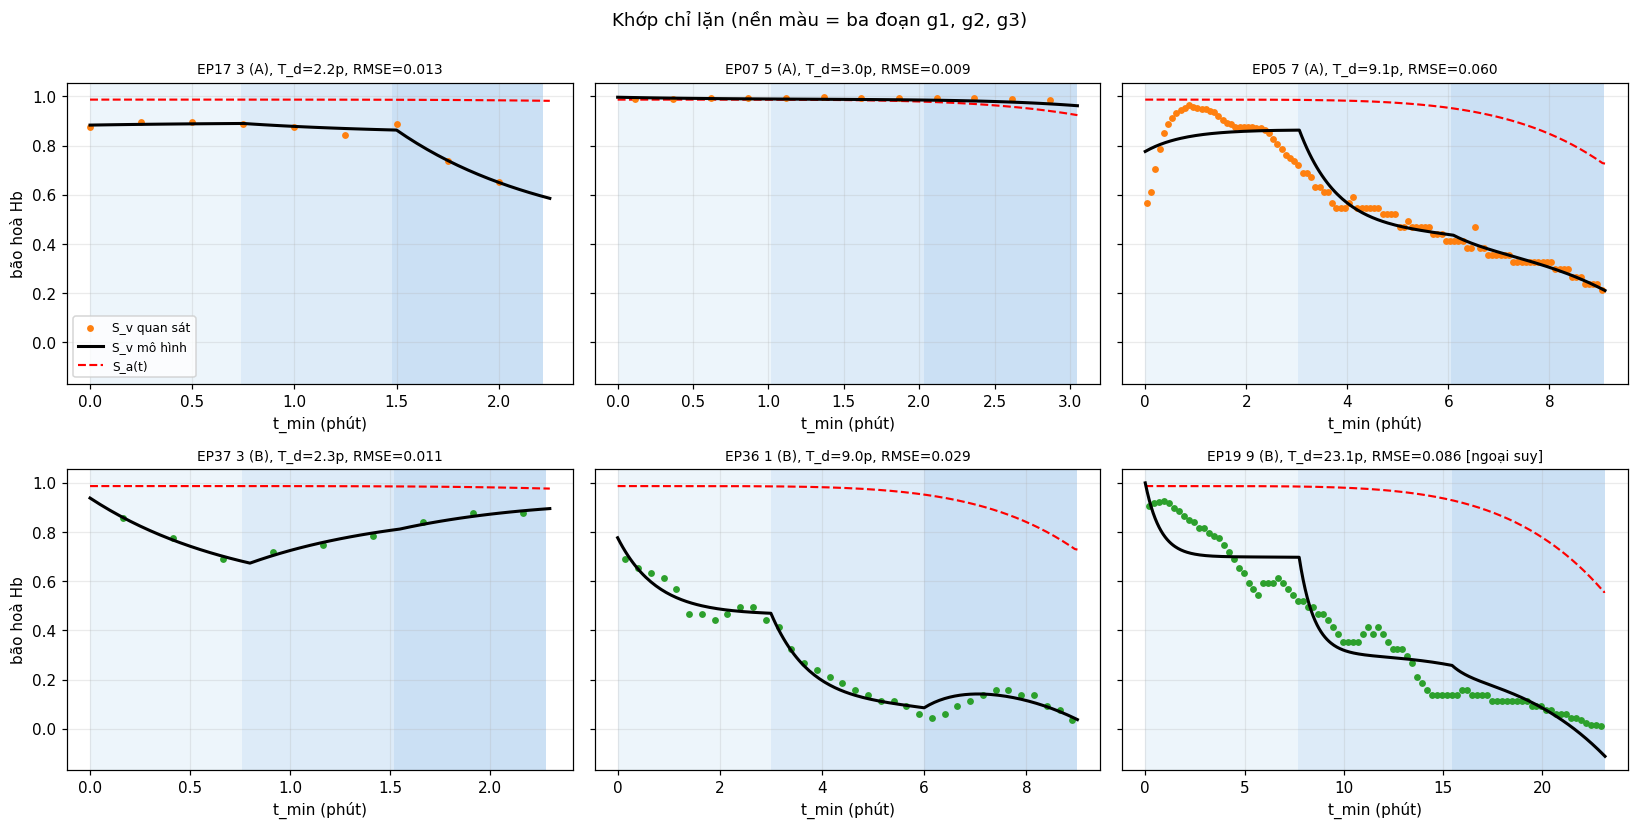

In [12]:
SEG_COL = {0: "#eeeeee", 1: "#dcecf9", 2: "#bcd9f2", 3: "#98c3ea", 4: "#fde3c4", 5: "#fbd0a0"}

def plot_fit(a, did, option):
    d = ven.loc[did]; Td = d["Td"]; g = WIN[did]
    T = F if option == "full" else G
    th = T.loc[did, [c for c in ["S_init"] + G_COLS if c in T.columns]].to_dict()
    if option == "dive":
        g = g[(g["t_min"] >= 0) & (g["t_min"] <= Td)]
        t0, t1 = 0.0, Td
    else:
        t0, t1 = max(-PRE_WIN_S / 60, g["t_min"].min()), g["t_min"].max()
    tg_, Sv_ = simulate_Sv(th, Td, R, TAU, t0, t1)
    for k, (lo_, hi_) in {0: (-6, 0), 1: (0, Td/3), 2: (Td/3, 2*Td/3), 3: (2*Td/3, Td), 4: (Td, Td+1), 5: (Td+1, Td+3), 6: (Td+3, Td+9)}.items():
        if option == "full":
            a.axvspan(lo_, hi_, color=SEG_COL.get(k if k < 6 else 0), alpha=0.5, lw=0)
    if option == "dive":
        for k, (lo_, hi_) in {1: (0, Td/3), 2: (Td/3, 2*Td/3), 3: (2*Td/3, Td)}.items():
            a.axvspan(lo_, hi_, color=SEG_COL[k], alpha=0.5, lw=0)
    a.scatter(g["t_min"], g["Hb"], s=12, color=COL[d["group"]], zorder=3, label="S_v quan sát")
    a.plot(tg_, Sv_, "k-", lw=2, zorder=4, label="S_v mô hình")
    a.plot(tg_, Sa_template(tg_, Td, TAU), "r--", lw=1.4, zorder=2, label="S_a(t)")
    flag = " [ngoại suy]" if d["extrapolated"] else ""
    a.set_title(f"{did} ({d['group'].split()[1]}), T_d={Td:.1f}p, RMSE={T.loc[did, 'rmse']:.3f}{flag}", fontsize=9)
    a.set_xlabel("t_min (phút)")

def pick_spread(T, grp, k):
    s = T[T["group"] == grp].sort_values("Td")
    if len(s) == 0: return []
    return list(s.index[np.unique(np.linspace(0, len(s) - 1, min(k, len(s))).astype(int))])

# (a) ví dụ cả chu kỳ: 4 type B (trải theo T_d) + type A nếu có
ids_ex = pick_spread(F, "Type B venous", 4) + pick_spread(F, "Type A venous", 2)
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for a, did in zip(axs.ravel(), ids_ex): plot_fit(a, did, "full")
for a in axs.ravel()[len(ids_ex):]: a.axis("off")
axs[0, 0].set_ylabel("bão hoà Hb"); axs[1, 0].set_ylabel("bão hoà Hb"); axs[0, 0].legend(fontsize=8)
fig.suptitle("Khớp cả chu kỳ (nền màu = các giai đoạn của g(t))", y=1.0); plt.tight_layout(); plt.show()

# (b) ví dụ chỉ lặn: 3 type A + 3 type B
ids_ex = pick_spread(G, "Type A venous", 3) + pick_spread(G, "Type B venous", 3)
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for a, did in zip(axs.ravel(), ids_ex): plot_fit(a, did, "dive")
axs[0, 0].set_ylabel("bão hoà Hb"); axs[1, 0].set_ylabel("bão hoà Hb"); axs[0, 0].legend(fontsize=8)
fig.suptitle("Khớp chỉ lặn (nền màu = ba đoạn g1, g2, g3)", y=1.0); plt.tight_layout(); plt.show()

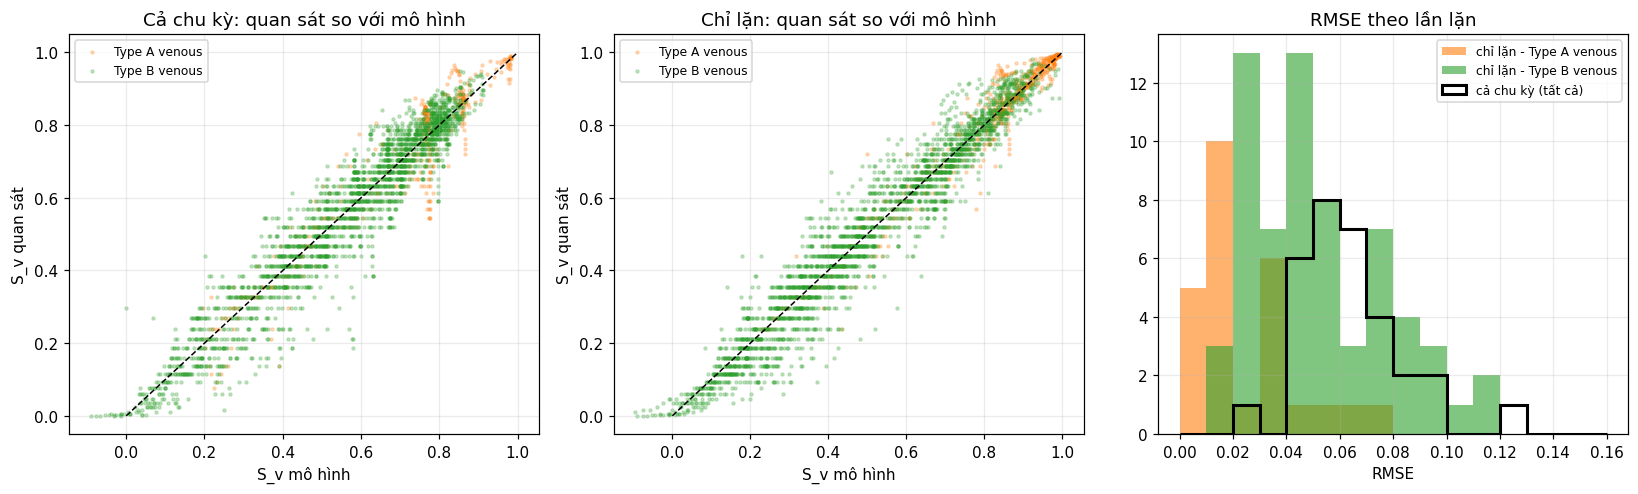

In [13]:
# (c) chất lượng khớp: quan sát so với mô hình và phân bố RMSE
def collect(option, ids):
    out = []
    for did in ids:
        d = ven.loc[did]; g = WIN[did]
        if option == "dive": g = g[(g["t_min"] >= 0) & (g["t_min"] <= d["Td"])]
        T = F if option == "full" else G
        th, pred = fit_dive(g["t_min"], g["Hb"], d["Td"], R, TAU, option)
        out.append(pd.DataFrame({"dive_id": did, "group": d["group"], "obs": g["Hb"].values, "pred": pred}))
    return pd.concat(out)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for k, (name, T, opt) in enumerate([("Cả chu kỳ", F, "full"), ("Chỉ lặn", G, "dive")]):
    P_ = collect(opt, T.index)
    for grp in ["Type A venous", "Type B venous"]:
        s = P_[P_["group"] == grp]; ax[k].scatter(s["pred"], s["obs"], s=4, alpha=0.25, color=COL[grp], label=grp)
    ax[k].plot([0, 1], [0, 1], "k--", lw=1); ax[k].set(title=f"{name}: quan sát so với mô hình", xlabel="S_v mô hình", ylabel="S_v quan sát"); ax[k].legend(fontsize=8)
bins = np.linspace(0, 0.16, 17)
for grp in ["Type A venous", "Type B venous"]:
    ax[2].hist(G.loc[G["group"] == grp, "rmse"], bins=bins, alpha=0.6, color=COL[grp], label=f"chỉ lặn - {grp}")
ax[2].hist(F["rmse"], bins=bins, histtype="step", lw=2, color="k", label="cả chu kỳ (tất cả)")
ax[2].set(title="RMSE theo lần lặn", xlabel="RMSE"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

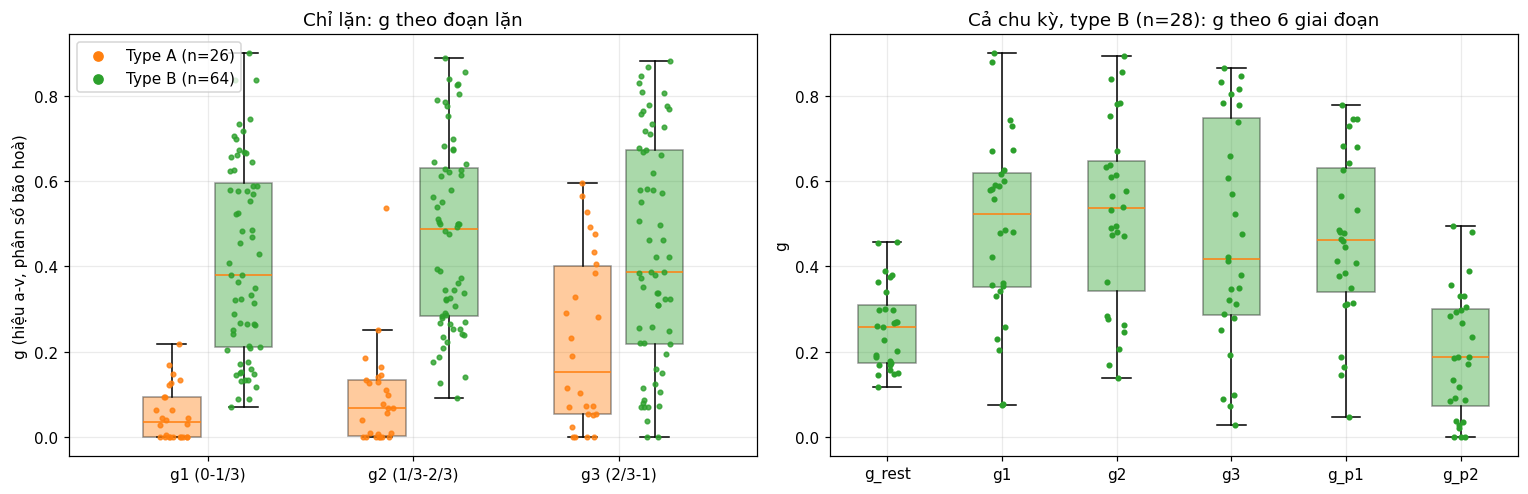

In [14]:
# (d) g theo giai đoạn: chỉ lặn (g1-g3, cả hai nhóm) và cả chu kỳ (6 giai đoạn, type B)
rng = np.random.default_rng(1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for k, grp in enumerate(["Type A venous", "Type B venous"]):
    s = G[G["group"] == grp]
    for j, c in enumerate(["g1", "g2", "g3"]):
        pos = j + (k - 0.5) * 0.35
        ax[0].boxplot(s[c], positions=[pos], widths=0.28, showfliers=False, patch_artist=True, boxprops=dict(facecolor=COL[grp], alpha=0.4))
        ax[0].scatter(pos + rng.uniform(-0.08, 0.08, len(s)), s[c], s=9, color=COL[grp], alpha=0.8, zorder=3)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["g1 (0-1/3)", "g2 (1/3-2/3)", "g3 (2/3-1)"])
ax[0].set(ylabel="g (hiệu a-v, phân số bão hoà)", title="Chỉ lặn: g theo đoạn lặn")
ax[0].scatter([], [], color=COL["Type A venous"], label=f"Type A (n={(G['group']=='Type A venous').sum()})")
ax[0].scatter([], [], color=COL["Type B venous"], label=f"Type B (n={(G['group']=='Type B venous').sum()})"); ax[0].legend()

s = F[F["group"] == "Type B venous"]; order = ["g_rest", "g1", "g2", "g3", "g_p1", "g_p2"]
ax[1].boxplot([s[c] for c in order], showfliers=False, patch_artist=True, boxprops=dict(facecolor=COL["Type B venous"], alpha=0.4))
for j, c in enumerate(order): ax[1].scatter(j + 1 + rng.uniform(-0.1, 0.1, len(s)), s[c], s=9, color=COL["Type B venous"], zorder=3)
ax[1].set_xticks(range(1, 7)); ax[1].set_xticklabels(order)
ax[1].set(title=f"Cả chu kỳ, type B (n={len(s)}): g theo 6 giai đoạn", ylabel="g")
plt.tight_layout(); plt.show()

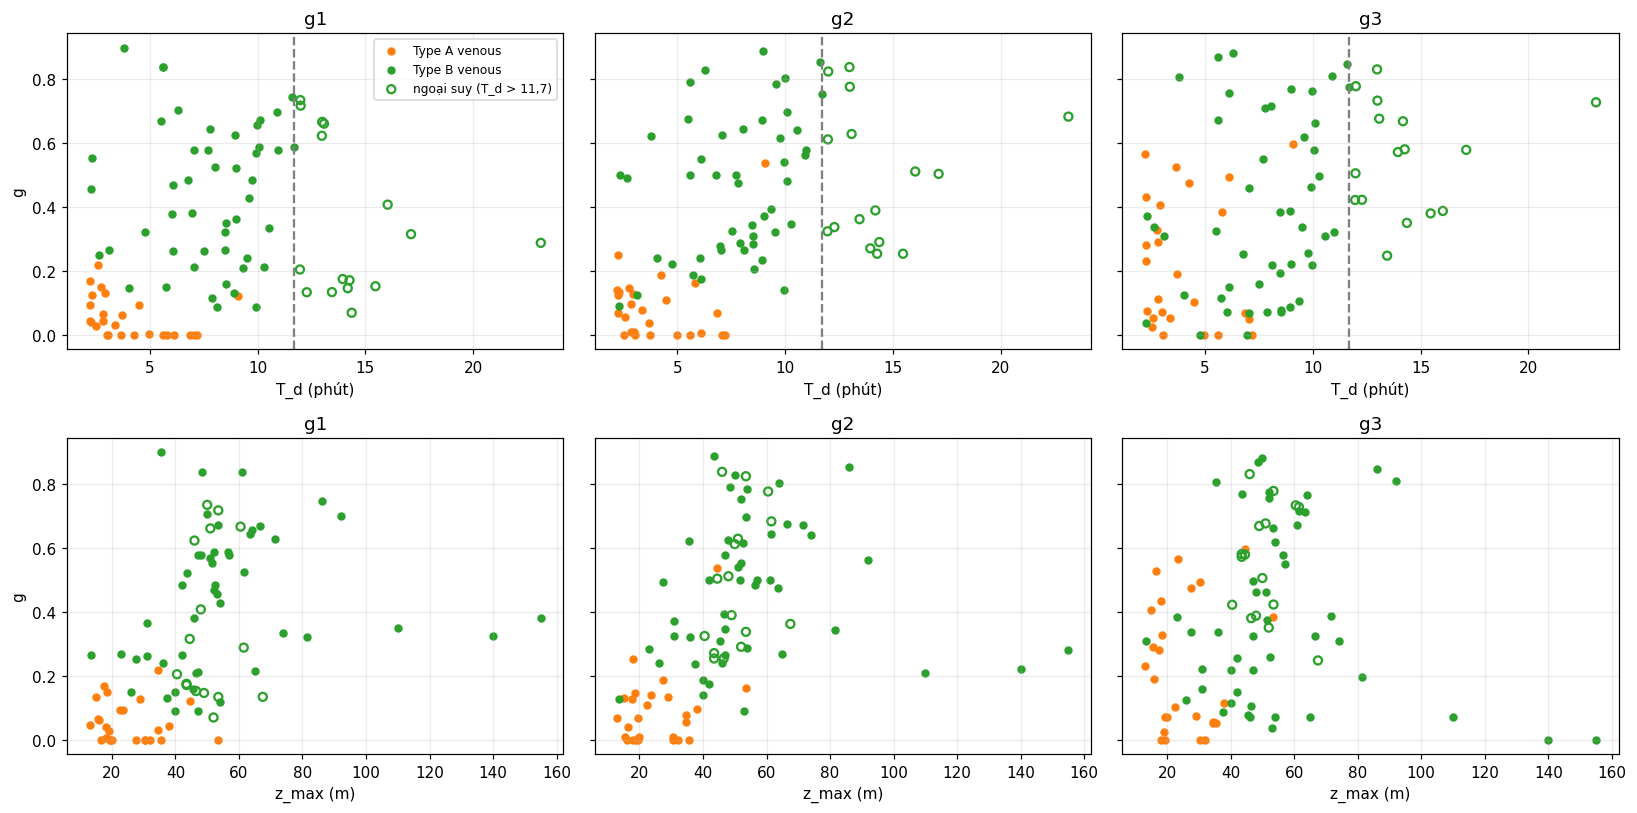

Tương quan Spearman của g với T_d và z_max (chỉ lặn, từng nhóm):


,nhóm,g,rho_Td,rho_zmax
0,Type A venous,g1,-0.53,-0.26
1,Type A venous,g2,-0.24,0.12
2,Type A venous,g3,-0.17,-0.14
3,Type B venous,g1,-0.12,0.36
4,Type B venous,g2,0.25,0.31
5,Type B venous,g3,0.36,0.12


In [15]:
# (e) g1-g3 phụ thuộc T_d và z_max (nhóm chỉ lặn); đánh dấu lần lặn ngoại suy (T_d > 11,7 phút)
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5), sharey="row")
for r_, xcol, xl in [(0, "Td", "T_d (phút)"), (1, "z_max", "z_max (m)")]:
    for c_, gc in enumerate(["g1", "g2", "g3"]):
        for grp in ["Type A venous", "Type B venous"]:
            s = G[G["group"] == grp]
            ok = s[~s["extrapolated"]]; ex = s[s["extrapolated"]]
            ax[r_, c_].scatter(ok[xcol], ok[gc], s=20, color=COL[grp], label=grp if (r_, c_) == (0, 0) else None)
            ax[r_, c_].scatter(ex[xcol], ex[gc], s=28, facecolors="none", edgecolors=COL[grp], linewidths=1.5,
                               label="ngoại suy (T_d > 11,7)" if (grp == "Type B venous" and (r_, c_) == (0, 0)) else None)
        if xcol == "Td": ax[r_, c_].axvline(TD_MAX_ART, color="gray", ls="--")
        ax[r_, c_].set(xlabel=xl, title=gc)
    ax[r_, 0].set_ylabel("g")
ax[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Tương quan Spearman của g với T_d và z_max (chỉ lặn, từng nhóm):")
rows = []
for grp in ["Type A venous", "Type B venous"]:
    s = G[G["group"] == grp]
    for gc in ["g1", "g2", "g3"]:
        rows.append({"nhóm": grp, "g": gc, "rho_Td": s[gc].corr(s["Td"], method="spearman"), "rho_zmax": s[gc].corr(s["z_max"], method="spearman")})
display(pd.DataFrame(rows).round(2))

31 lần lặn có cả hai kết quả


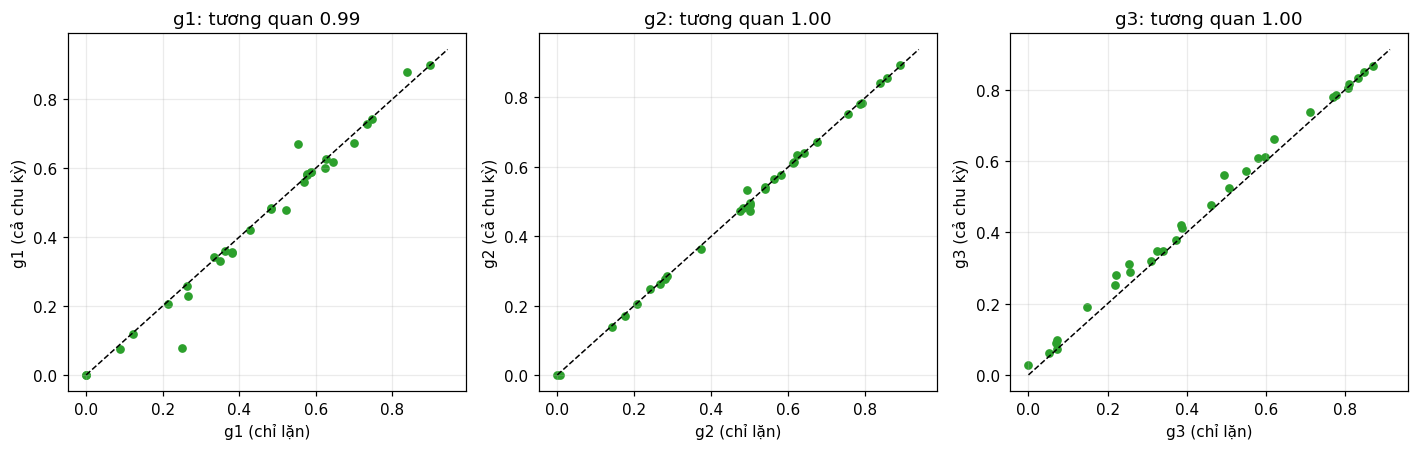

In [16]:
# (f) hai phương án có cho cùng g1-g3 trên các lần lặn có cả hai kết quả không?
both = F.join(G, lsuffix="_full", rsuffix="_dive", how="inner")
print(f"{len(both)} lần lặn có cả hai kết quả")
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
for a, gc in zip(ax, ["g1", "g2", "g3"]):
    a.scatter(both[f"{gc}_dive"], both[f"{gc}_full"], s=22, color=COL["Type B venous"])
    lim = [0, max(both[f"{gc}_dive"].max(), both[f"{gc}_full"].max()) * 1.05 + 1e-6]
    a.plot(lim, lim, "k--", lw=1); a.set(xlabel=f"{gc} (chỉ lặn)", ylabel=f"{gc} (cả chu kỳ)", title=f"{gc}: tương quan {both[f'{gc}_dive'].corr(both[f'{gc}_full']):.2f}")
plt.tight_layout(); plt.show()

## 8b. Giới hạn của mô hình: sàn $S_v=0$ và lần lặn ngoại suy

Phương trình E2 không có sàn: $S_v$ mô hình có thể đi dưới 0, trong khi dữ liệu dừng ở 0 (hết oxy). Ô dưới đếm mức độ ảnh hưởng, và so sánh $g$ giữa lần lặn type B trong và ngoài giới hạn $T_d\le 11{,}7$ phút.

In [17]:
vd = ts[(ts["site"] == "venous") & ts["dive_id"].notna() & ~ts["excluded_dive"]].copy()
vd["group"] = vd["dive_id"].map(dv["group"])
print("Tỉ lệ mẫu trong lặn có S_v <= 0,02 (chạm sàn 0):")
display(vd.groupby("group")["Hb"].apply(lambda s_: (s_ <= 0.02).mean()).round(3).to_frame("ti_le"))

def model_min(did, option):
    d = ven.loc[did]; Td = d["Td"]; g = WIN[did]
    T = F if option == "full" else G
    th = T.loc[did, [c for c in ["S_init"] + G_COLS if c in T.columns]].to_dict()
    t0, t1 = (0.0, Td) if option == "dive" else (max(-PRE_WIN_S / 60, g["t_min"].min()), g["t_min"].max())
    return simulate_Sv(th, Td, R, TAU, t0, t1)[1].min()

chk = pd.concat([
    pd.DataFrame({"phuong_an": name, "group": T["group"].values, "extrapolated": T["extrapolated"].values,
                  "S_v_min": [model_min(i, opt) for i in T.index]})
    for name, T, opt in [("cả chu kỳ", F, "full"), ("chỉ lặn", G, "dive")]])
chk["duoi_0"] = chk["S_v_min"] < -0.02
print("S_v mô hình có đi xuống dưới 0 không? (đếm lần lặn có min < −0,02)")
display(chk.groupby(["phuong_an", "group"]).agg(so_lan_lan=("S_v_min", "size"), mo_hinh_duoi_0=("duoi_0", "sum"),
                                               S_v_min_trung_vi=("S_v_min", "median")).round(3))

print("Type B, chỉ lặn: g theo việc có ngoại suy (T_d > 11,7) hay không")
sB = G[G["group"] == "Type B venous"]
display(sB.groupby("extrapolated").agg(n=("Td", "size"), g1=("g1", "median"), g2=("g2", "median"), g3=("g3", "median"), rmse=("rmse", "median")).round(3))

Tỉ lệ mẫu trong lặn có S_v <= 0,02 (chạm sàn 0):


,ti_le
group,
Type A venous,0.000
Type B venous,0.011


S_v mô hình có đi xuống dưới 0 không? (đếm lần lặn có min < −0,02)


so_lan_lan  mo_hinh_duoi_0  S_v_min_trung_vi
phuong_an group                                                      
chỉ lặn   Type A venous          26               0             0.722
          Type B venous          64               5             0.325
cả chu kỳ Type A venous           3               0             0.357
          Type B venous          28               4             0.254

Type B, chỉ lặn: g theo việc có ngoại suy (T_d > 11,7) hay không


,n,g1,g2,g3,rmse
extrapolated,,,,,
False,48,0.442,0.488,0.331,0.044
True,16,0.246,0.447,0.576,0.069


## 9. Type A và type B có khác nhau không? (phương án chỉ lặn)

Trung vị của $g_1,g_2,g_3$ theo nhóm với khoảng tin cậy bootstrap theo lần lặn, và kiểm định Mann–Whitney. Ngoài ra ô cuối kiểm tra độ nhạy của kết quả với giá trị $r$ (vì ghi chú không cho $r$).

,g,A_trung_vi,A_KTC95,B_trung_vi,B_KTC95,p_MannWhitney
0,g1,0.0345,0.000-0.078,0.3804,0.278-0.524,0.0000
1,g2,0.0687,0.008-0.126,0.4877,0.345-0.546,0.0000
2,g3,0.1523,0.062-0.329,0.3876,0.324-0.539,0.0006


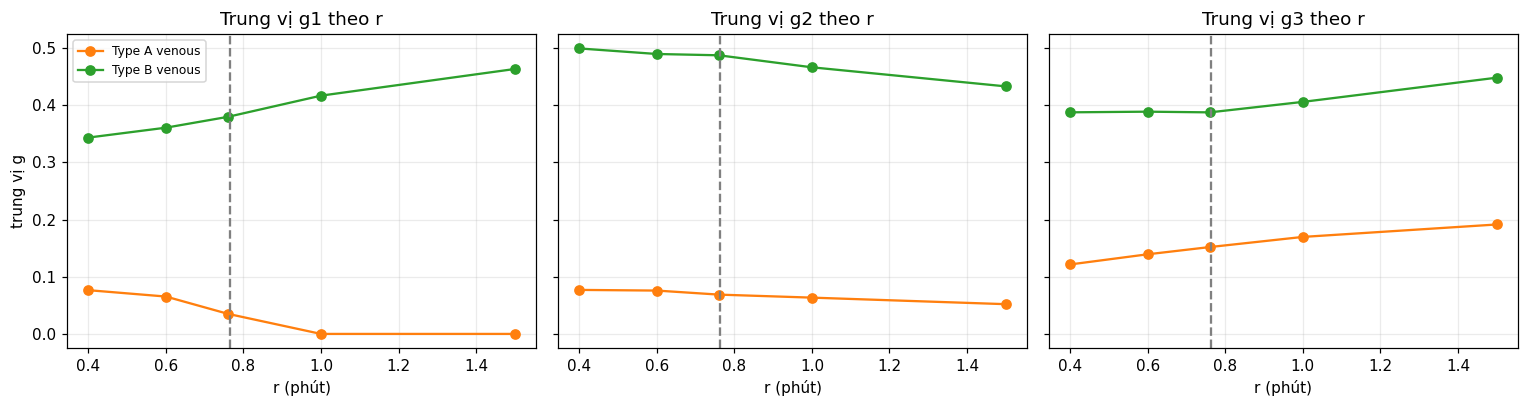

In [18]:
rng = np.random.default_rng(SEED)
def boot_median(v, B=2000):
    v = np.asarray(v); return np.percentile([np.median(rng.choice(v, len(v))) for _ in range(B)], [2.5, 97.5])

rows = []
for gc in ["g1", "g2", "g3"]:
    a_ = G.loc[G["group"] == "Type A venous", gc].values; b_ = G.loc[G["group"] == "Type B venous", gc].values
    ca, cb = boot_median(a_), boot_median(b_)
    p = mannwhitneyu(a_, b_, alternative="two-sided").pvalue
    rows.append({"g": gc, "A_trung_vi": np.median(a_), "A_KTC95": f"{ca[0]:.3f}-{ca[1]:.3f}", "B_trung_vi": np.median(b_),
                 "B_KTC95": f"{cb[0]:.3f}-{cb[1]:.3f}", "p_MannWhitney": p})
display(pd.DataFrame(rows).round(4))

# độ nhạy với r
r_list = sorted(set([0.4, 0.6, round(R, 2), 1.0, 1.5]))
sens = []
for rr_ in r_list:
    rows_ = []
    for did in G.index:
        d = ven.loc[did]; g = WIN[did]; g = g[(g["t_min"] >= 0) & (g["t_min"] <= d["Td"])]
        th, _ = fit_dive(g["t_min"], g["Hb"], d["Td"], rr_, TAU, "dive")
        rows_.append({"group": d["group"], **{k: th[k] for k in ["g1", "g2", "g3"]}})
    m_ = pd.DataFrame(rows_).groupby("group").median()
    for grp in m_.index:
        for gc in ["g1", "g2", "g3"]: sens.append({"r": rr_, "group": grp, "g": gc, "median": m_.loc[grp, gc]})
S = pd.DataFrame(sens)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a, gc in zip(ax, ["g1", "g2", "g3"]):
    for grp in ["Type A venous", "Type B venous"]:
        s = S[(S["g"] == gc) & (S["group"] == grp)]; a.plot(s["r"], s["median"], "o-", color=COL[grp], label=grp)
    a.axvline(R, color="gray", ls="--"); a.set(title=f"Trung vị {gc} theo r", xlabel="r (phút)")
ax[0].set_ylabel("trung vị g"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 10. Xuất kết quả

In [19]:
F.reset_index().to_csv(f"{DIR}/venous_fit_full_cycle.csv", index=False)
G.reset_index().to_csv(f"{DIR}/venous_fit_dive_only.csv", index=False)
W.reset_index().to_csv(f"{DIR}/venous_windows.csv", index=False)

params = {
    "constants": {"P50": P50, "n_hill": N_HILL, "S_REST": S_REST, "S_DIVE0": S_DIVE0, "K_EXP": K_EXP,
                  "dSa_formula": "clip(-0.141 + 0.183 ln Td, 0, 0.6)", "TD_MAX_ART": TD_MAX_ART, "DT_MIN": DT_MIN},
    "estimated": {"tau_a_min": TAU, "tau_a_ci95": [float(tau_ci[0]), float(tau_ci[1])], "r_min": R},
    "counts": {"n_full_cycle": int(len(F)), "n_dive_only": int(len(G)), "n_clean_windows": int(W["clean"].sum()),
               "n_venous_dives": int(len(W))},
}
with open(f"{DIR}/model_params.json", "w", encoding="utf-8") as fh:
    json.dump(params, fh, ensure_ascii=False, indent=2)
print("Đã xuất: venous_fit_full_cycle.csv | venous_fit_dive_only.csv | venous_windows.csv | model_params.json ->", DIR)

Đã xuất: venous_fit_full_cycle.csv | venous_fit_dive_only.csv | venous_windows.csv | model_params.json -> ../data
